# Задача классификации
Датасет **Titanic-Dataset**: 
- целевая переменная - **Survived** 


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import kagglehub
from kagglehub import KaggleDatasetAdapter

%matplotlib inline
sns.set_theme(style="darkgrid")

file_path = "Titanic-Dataset.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "yasserh/titanic-dataset",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)


pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print(df.shape)
print(df.head())
print(df["Survived"].describe())

print("Количество пропусков в каждом столбце:")
display(df.isna().sum().to_frame(name="missing_values").T)
print(f"Количество полных дубликатов строк: {df.duplicated().sum()}")

c:\Users\danii\Desktop\MAI\ML\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN    

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
missing_values,0,0,0,0,0,177,0,0,0,0,687,2


Количество полных дубликатов строк: 0


**Объем и целостность данных:** Датасет содержит 891 объект и 12 столбцов (числовые: `Age`, `Fare`, `SibSp`, `Parch`; порядковые/бинарные: `Survived`, `Pclass`; строковые/категориальные: `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`). Полных дубликатов строк нет. Много пропусков номера кабины, меньше - возраст и порт посадки

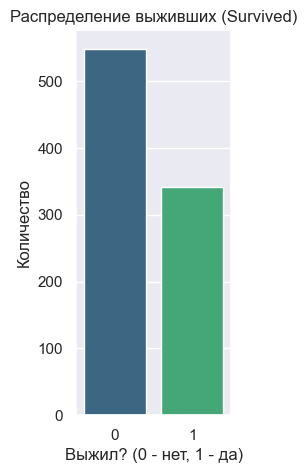

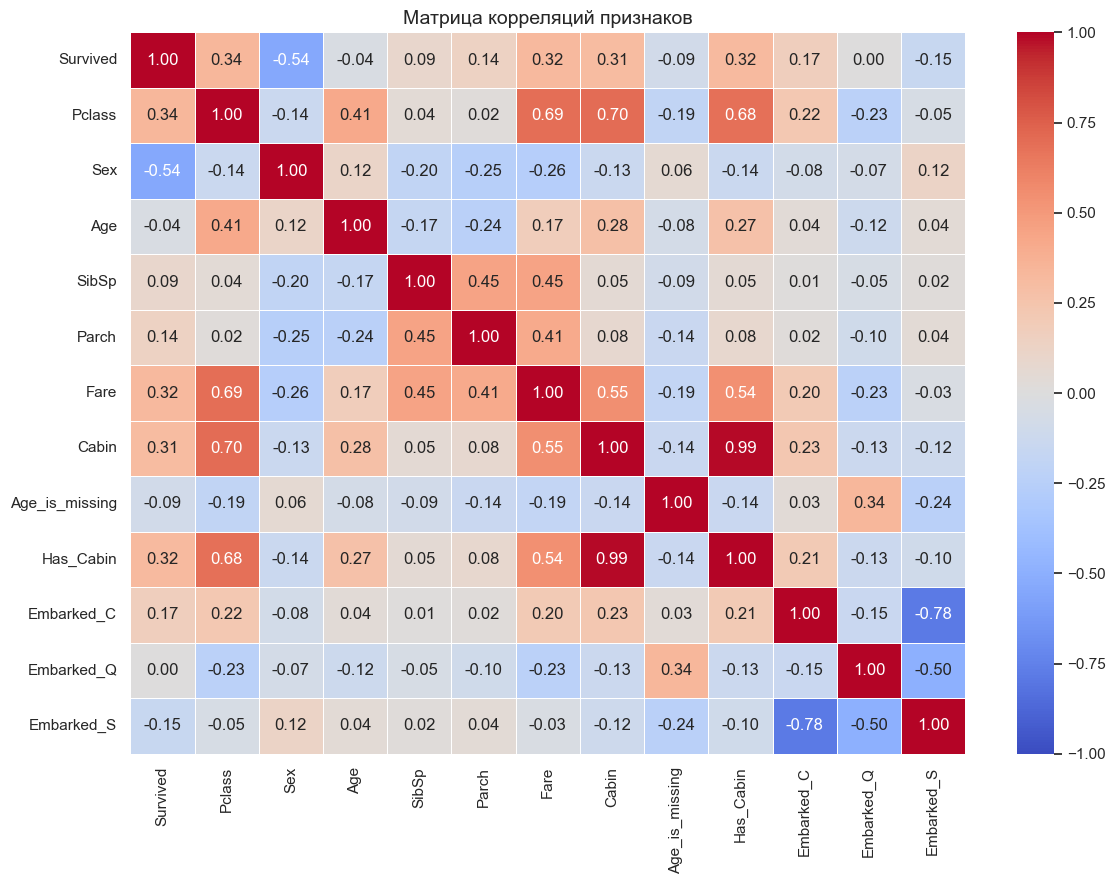

In [3]:
plt.figure(figsize=(2, 5))
ax = sns.countplot(data=df, x="Survived", hue="Survived", palette="viridis", legend=False)
plt.title("Распределение выживших (Survived)")
plt.xlabel("Выжил? (0 - нет, 1 - да)")
plt.ylabel("Количество")
plt.show()

    
def extract_deterministic_features(df_in):
    d = df_in.copy()
    
    d['Age_is_missing'] = d['Age'].isna().astype(int)
    d['Has_Cabin'] = d['Cabin'].notna().astype(int)
    
    cabin_map = {'A': 8, 'B': 7, 'C': 6, 'D': 5, 'E': 4, 'F': 3, 'G': 2, 'T': 1}
    d['Cabin'] = d['Cabin'].str[0].map(cabin_map).fillna(0).astype(int)
    
    d['Sex'] = d['Sex'].map({'male': 1, 'female': 0})
    d['Pclass'] = d['Pclass'].map({1: 3, 2: 2, 3: 1})
    return d

df_filled = df.copy()
df_filled = extract_deterministic_features(df_filled)

most_freq_port = df_filled['Embarked'].mode()[0]
df_filled['Embarked'] = df_filled['Embarked'].fillna(most_freq_port)
df_filled = pd.get_dummies(df_filled, columns=['Embarked'], drop_first=False, dtype=int)

df_filled = df_filled.drop(columns=["Name", "Ticket", "PassengerId"])

df_filled['Age'] = df_filled['Age'].fillna(df_filled.groupby(['Pclass', 'Sex'])['Age'].transform('median'))

corr_matrix = df_filled.corr(method='spearman', numeric_only=True)
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5
)

plt.title("Матрица корреляций признаков", fontsize=14)
plt.tight_layout()
plt.show()

### Выводы по первичному анализу данных:
1. **Баланс классов:** Целевая переменная `Survived` несбалансирована — выжило около 38.4% пассажиров (класс `1`), погибло 61.6% (класс `0`). Поэтому при разбиении выборки необходима стратификация.
2. **Неинформативные признаки:** Столбцы `PassengerId`, `Name` и `Ticket` являются уникальными идентификаторами пассажиров. Их прямое использование приведет к бессмысленному запоминанию объектов моделью, поэтому при обучении они удаляются.
3. **Корреляционный анализ:** Сильной корреляции (>= 0.7) с целевой переменной `Survived` ни у одного признака не наблюдается. Наиболее сильная связь с выживаемостью наблюдается у признаков `Sex` (-0.54 - женщины выживали значительно чаще мужчин), `Pclass` (0.34), `Fare` (0.32) и `Cabin` (0.31). Между уровнем палубы `Cabin` и синтетическим бинарным флагом `Has_Cabin` обнаружена мультиколлинеарность (0.99), поэтому избыточный признак `Has_Cabin` исключен из итогового пайплайна.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


RANDOM_STATE = 42

class GroupMedianAgeImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.group_medians_ = X.groupby(['Pclass', 'Sex'])['Age'].median()
        self.global_median_ = X['Age'].median()
        return self

    def transform(self, X):
        X_out = X.copy()
        mapped_age = (
            X_out.set_index(['Pclass', 'Sex'])
            .index.map(self.group_medians_)
            .to_series(index=X_out.index)
        )
        X_out['Age'] = X_out['Age'].fillna(mapped_age).fillna(self.global_median_)
        return X_out

numeric_features = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass', 'Cabin', 'Sex', 'Age_is_missing']
categorical_features = ['Embarked']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

column_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

preprocessor = Pipeline(steps=[
    ('feature_extraction', FunctionTransformer(extract_deterministic_features)),
    ('age_group_imputer', GroupMedianAgeImputer()),
    ('column_processing', column_preprocessor)
])

### Обоснование предобработки данных и масштабирования:
1. **Защита от утечки данных:** Разбиение на `train` и `test` (80% / 20%) выполнено со стратификацией по целевой переменной (`stratify=y`) и фиксированным `random_state=42`. Все трансформеры обучаются строго на `X_train` внутри единого `Pipeline`.
2. **Обработка пропусков и категорий:**
   * `Embarked` (2 пропуска): заполняется модой (`most_frequent`) и кодируется через `OneHotEncoder` в 3 бинарных признака, так как между портами посадки нельзя определить, какой больше влияет на выживаемость.
   * `Cabin` (687 пропусков): извлекается первая буква палубы и переводится в порядковую шкалу от `1` (нижняя палуба `T`) до `8` (верхняя палуба `A`), а пропуски кодируются как `0`.
   * `Age` (177 пропусков): заполняется медианным возрастом внутри групп `['Pclass', 'Sex']` (с помощью кастомного трансформера `GroupMedianAgeImputer`), так как возраст заметно коррелирует с классом билета (0.41). Дополнительно сохраняется бинарный индикатор пропуска `Age_is_missing`.
3. **Зачем и каким моделям нужно масштабирование (`StandardScaler`):**
   * Масштабирование **важно для KNN и SVM**. `KNN` вычисляет евклидово расстояние между объектами: без нормализации признак `Fare` (значения до 512) полностью подавит вклад бинарного признака `Sex` (0 или 1) и класса `Pclass` (1..3). `SVM` с RBF-ядром также опирается на расстояния и ширину разделяющей полосы в пространстве признаков.
   * Для **Decision Tree, Random Forest, Gradient Boosting** масштабирование не влияет на качество, так как деревья ищут пороговые разбиения по каждому признаку независимо.

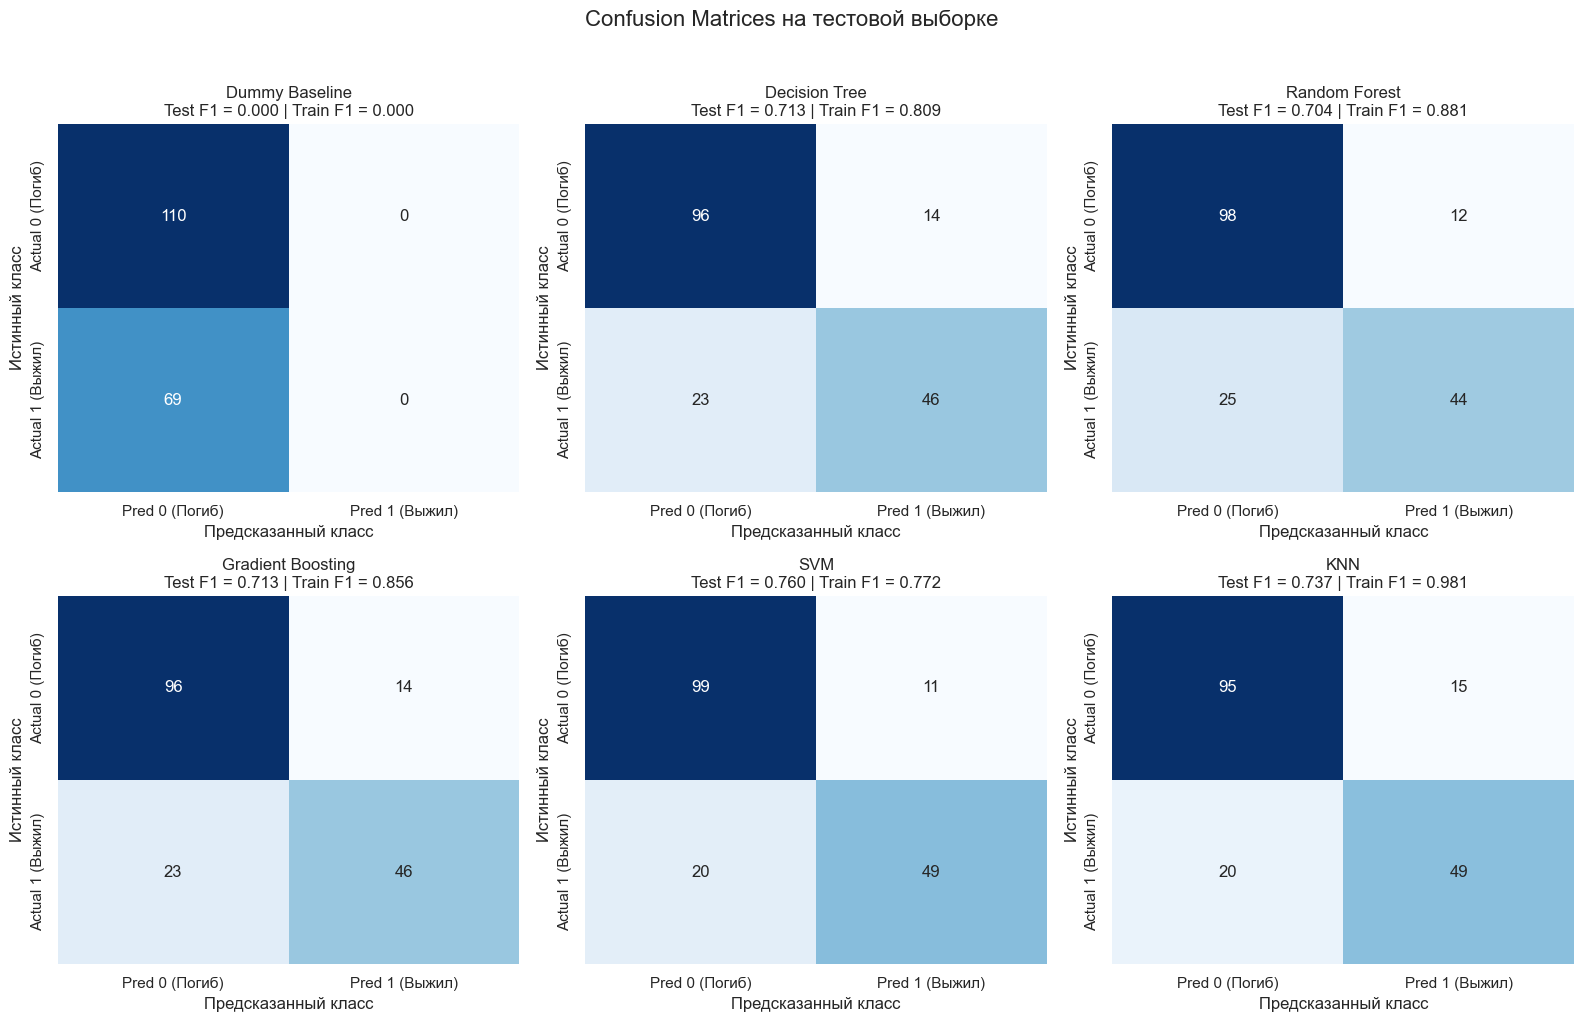

,Model,Accuracy,Precision,Recall,F1 (Test),F1 (Train),F1 (CV 5-fold),Pass (F1 > 0.70)
4,SVM,0.8268,0.8167,0.7101,0.7597,0.7716,0.7449,Да
5,KNN,0.8045,0.7656,0.7101,0.7368,0.9814,0.7334,Да
3,Gradient Boosting,0.7933,0.7667,0.6667,0.7132,0.8555,0.7586,Да
1,Decision Tree,0.7933,0.7667,0.6667,0.7132,0.8092,0.7318,Да
2,Random Forest,0.7933,0.7857,0.6377,0.7040,0.8806,0.7582,Да
0,Dummy Baseline,0.6145,0.0000,0.0000,0.0000,0.0000,0.0000,Нет


In [28]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=2, random_state=RANDOM_STATE),
    "SVM": SVC(kernel="rbf", C=0.5, gamma="scale", random_state=RANDOM_STATE, probability=True),
    "KNN": KNeighborsClassifier(n_neighbors=9, weights="distance")
}


results = []
trained_pipelines = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    y_train_pred = pipe.predict(X_train)
    y_test_pred = pipe.predict(X_test)
    
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1').mean()
    
    acc = accuracy_score(y_test, y_test_pred)
    prec = precision_score(y_test, y_test_pred, zero_division=0)
    rec = recall_score(y_test, y_test_pred, zero_division=0)
    f1_test = f1_score(y_test, y_test_pred, zero_division=0)
    f1_train = f1_score(y_train, y_train_pred, zero_division=0)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 (Test)": f1_test,
        "F1 (Train)": f1_train,
        "F1 (CV 5-fold)": cv_f1,
        "Pass (F1 > 0.70)": "Да" if f1_test > 0.70 else "Нет"
    })
    
    cm = confusion_matrix(y_test, y_test_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
        xticklabels=["Pred 0 (Погиб)", "Pred 1 (Выжил)"],
        yticklabels=["Actual 0 (Погиб)", "Actual 1 (Выжил)"]
    )
    axes[idx].set_title(f"{name}\nTest F1 = {f1_test:.3f} | Train F1 = {f1_train:.3f}")
    axes[idx].set_ylabel("Истинный класс")
    axes[idx].set_xlabel("Предсказанный класс")

plt.suptitle("Confusion Matrices на тестовой выборке", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

leaderboard_df = pd.DataFrame(results).sort_values(by="F1 (Test)", ascending=False)
display(leaderboard_df.round(4))

### Анализ метрик, матриц ошибок (Confusion Matrices) и сравнение моделей:

1. **Преодоление порога качества ($F1 > 0.70$):**
   * `Dummy Baseline` всегда предсказывает наиболее частый класс (`0` — погиб), поэтому у него `Accuracy = 0.6145`, но для целевого класса `Survived = 1` все метрики равны нулю (`Precision = 0.0000`, `Recall = 0.0000`, `F1 = 0.0000`). Это наглядно показывает, почему `Accuracy` не подходит для несбалансированных выборок.
   * **Все 5 остальных моделей успешно преодолели порог $F1 > 0.70$ на тестовой выборке:** лидирует `SVM` (`F1 = 0.7597`, `Accuracy = 0.8268`), за ним следуют `KNN` (`F1 = 0.7368`, `Accuracy = 0.8045`), `Gradient Boosting` и `Decision Tree` (разделили 3-е место на тесте с `F1 = 0.7132` и `Accuracy = 0.7933`), а замыкает пятерку `Random Forest` (`F1 = 0.7040`, `Accuracy = 0.7933`). При этом на 5-фолдовой кросс-валидации наивысшую стабильность показали ансамбли: `Gradient Boosting` (`F1 CV = 0.7586`) и `Random Forest` (`F1 CV = 0.7582`).

2. **Различие между ошибками False Positive (FP) и False Negative (FN):**
   * **False Positive (FP, верхний правый угол матрицы):** модель предсказала, что пассажир выжил (`1`), но в реальности он погиб (`0`).
   * **False Negative (FN, нижний левый угол матрицы):** модель предсказала гибель (`0`), хотя пассажир на самом деле спасся (`1`).
   * У всех пяти содержательных моделей `Precision` (`0.7656–0.8167`) заметно выше `Recall` (`0.6377–0.7101`). По матрицам ошибок видно, что модели чаще совершают ошибки **False Negative** (от 20 до 25 пропущенных выживших против 11–15 ошибок FP). Поскольку погибших в выборке большинство (61.6%), алгоритмы более консервативны при назначении класса `1`.

3. **Анализ переобучения и влияние гиперпараметров:**
   * **Decision Tree (`max_depth=10, min_samples_leaf=10`):** за счет ограничения минимального числа объектов в листе удалось избежать заучивания тренировочной выборки (`F1 Train = 0.8092`, `F1 CV = 0.7318`, `F1 Test = 0.7132`). Разрыв между обучением и тестом составляет допустимые ~9.6%.
   * **Random Forest (`n_estimators=150, min_samples_leaf=2`) и Gradient Boosting (`n_estimators=200, max_depth=2`):** показывают умеренный зазор между трейном (`0.8806` и `0.8555`) и кросс-валидацией (`0.7582` и `0.7586`). Оба ансамбля дают лучшее качество на кросс-валидации среди всех моделей за счет снижения дисперсии (в случайном лесе) и последовательной коррекции ошибок неглубокими деревьями (в бустинге).
   * **KNN (`n_neighbors=9, weights="distance"`):** демонстрирует **выраженное переобучение на обучающей выборке (`F1 Train = 0.9814` при `F1 Test = 0.7368`)**. Причина в параметре `weights="distance"`: при оценке на `X_train` ближайшим соседом каждого объекта оказывается он сам (расстояние равно $0$, вес стремится к бесконечности), поэтому алгоритм идеально запоминает тренировочные точки, кроме редких полных дубликатов с разными метками. Однако благодаря `n_neighbors=9` и масштабированию `StandardScaler` на новых данных (`Test`) модель обобщает хорошо (`F1 = 0.7368`).
   * **SVM (`kernel="rbf", C=0.5`):** показал **лучшую обобщающую способность и минимальный разрыв между обучением и тестом** (`F1 Train = 0.7716`, `F1 CV = 0.7449`, `F1 Test = 0.7597`). Снижение параметра регуляризации до `C=0.5` расширило разделяющую полосу и предотвратило подстройку под шумовые выбросы.

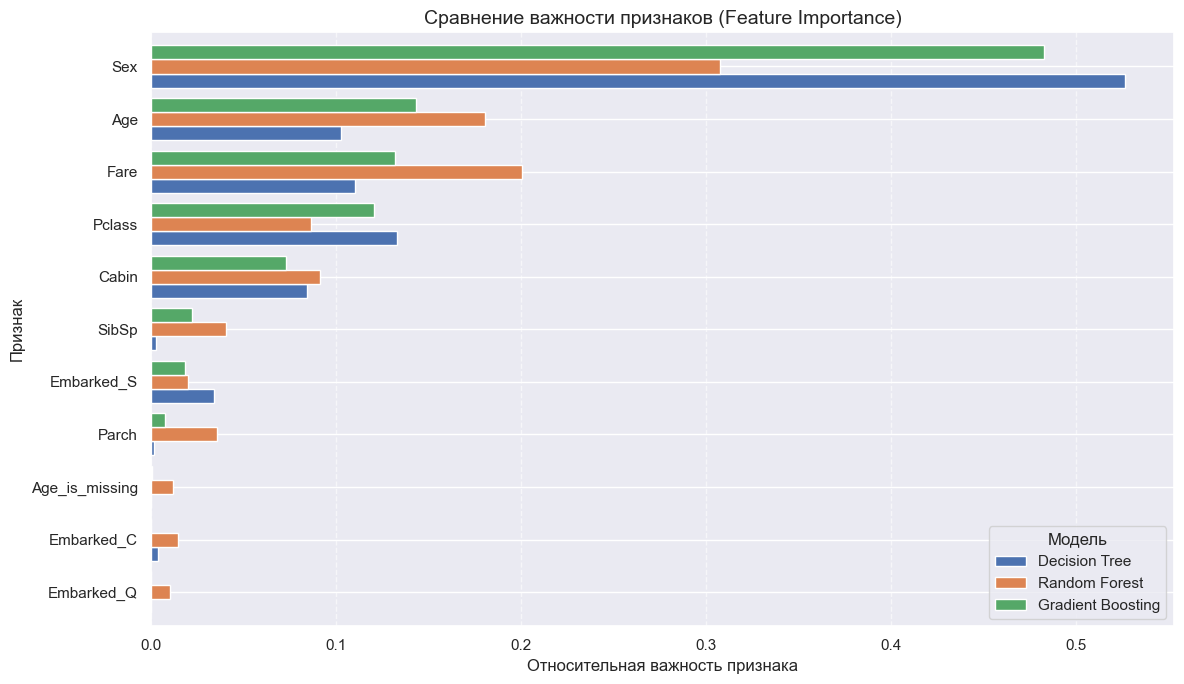

In [29]:
ohe_categories = (
    trained_pipelines["Gradient Boosting"] #берём любой, препроцессор у всех одинаковый
    .named_steps['preprocessor']
    .named_steps['column_processing']
    .named_transformers_['cat']
    .named_steps['onehot']
    .get_feature_names_out(categorical_features)
)
all_feature_names = numeric_features + list(ohe_categories)

tree_models = ["Decision Tree", "Random Forest", "Gradient Boosting"]
fi_data = {}

for name in tree_models:
    clf = trained_pipelines[name].named_steps['classifier']
    fi_data[name] = clf.feature_importances_

fi_df = pd.DataFrame(fi_data, index=all_feature_names)
fi_df = fi_df.sort_values(by="Gradient Boosting", ascending=True)

ax = fi_df.plot(kind="barh", figsize=(12, 7), width=0.8)
plt.title("Сравнение важности признаков (Feature Importance)", fontsize=14)
plt.xlabel("Относительная важность признака")
plt.ylabel("Признак")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.legend(title="Модель")
plt.tight_layout()
plt.show()

### Выводы по важности признаков (Feature Importance):
1. **Наиболее важные признаки:** Во всех трех деревянных моделях с огромным отрывом лидирует признак пола `Sex`. В число ключевых признаков также входят стоимость билета (`Fare`), статус класса (`Pclass`), возраст (`Age`) и уровень палубы (`Cabin`).
2. **Сравнение Decision Tree, Random Forest и Gradient Boosting:**
   * В `Decision Tree` (с ограничением `min_samples_leaf=10`) и `Gradient Boosting` (`max_depth=2`) основная разделяющая способность сконцентрирована в 4–5 главных признаках (`Sex`, `Pclass`, `Fare`, `Age`, `Cabin`), а редкие бинарные флаги (`Age_is_missing`, `Embarked_Q`) практически не используются в сплитах.
   * `Random Forest` (`min_samples_leaf=2`) строит более глубокие деревья на случайных подмножествах признаков, поэтому сильнее задействует непрерывные признаки `Fare` и `Age` для детального разбиения объектов.
3. **Сопоставление с выводами первичного анализа:** Результаты полностью согласуются с матрицей корреляций, где именно `Sex` (-0.54), `Pclass` (0.34), `Fare` (0.32) и `Cabin` (0.31) показали наиболее выраженную связь с выживаемостью. Признак `Age`, имевший слабую монотонную корреляцию с таргетом (-0.04), вошел в топ-4 важнейших признаков для деревьев благодаря нелинейным пороговым правилам (приоритетное спасение детей).

In [30]:
best_model_name = leaderboard_df.iloc[0]["Model"]
best_pipe = trained_pipelines[best_model_name]

test_analysis = X_test.copy()
test_analysis["Actual_Survived"] = y_test
test_analysis["Pred_Survived"] = best_pipe.predict(X_test)

fp_cases = test_analysis[(test_analysis["Actual_Survived"] == 0) & (test_analysis["Pred_Survived"] == 1)]
fn_cases = test_analysis[(test_analysis["Actual_Survived"] == 1) & (test_analysis["Pred_Survived"] == 0)]

print(f"Лучшая модель: {best_model_name}")
print(f"Количество ошибок False Positive (ложно спасли): {len(fp_cases)}")
print(f"Количество ошибок False Negative (не заметили выжившего): {len(fn_cases)}\n")

print("Примеры False Positive:")
display(fp_cases[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin"]].head(5))

print("\nПримеры False Negative:")
display(fn_cases[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin"]].head(5))


print("Распределение ошибок по полу и классу билета (Pclass x Sex):")
error_groups = test_analysis[test_analysis["Actual_Survived"] != test_analysis["Pred_Survived"]].groupby(["Pclass", "Sex", "Actual_Survived", "Pred_Survived"]).size()
display(error_groups.to_frame(name="Count"))

Лучшая модель: SVM
Количество ошибок False Positive (ложно спасли): 11
Количество ошибок False Negative (не заметили выжившего): 20

Примеры False Positive:


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin
27,1,male,19.0,3,2,263.0000,C23 C25 C27
297,1,female,2.0,1,2,151.5500,C22 C26
40,3,female,40.0,1,0,9.4750,NaN
564,3,female,NaN,0,0,8.0500,NaN
502,3,female,NaN,0,0,7.6292,NaN



Примеры False Negative:


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin
553,3,male,22.0,0,0,7.2250,NaN
712,1,male,48.0,1,0,52.0000,C126
455,3,male,29.0,0,0,7.8958,NaN
65,3,male,NaN,1,1,15.2458,NaN
489,3,male,9.0,1,1,15.9000,NaN


Распределение ошибок по полу и классу билета (Pclass x Sex):


Count
Pclass Sex    Actual_Survived Pred_Survived       
1      female 0               1                  1
       male   0               1                  1
              1               0                  8
2      female 0               1                  1
       male   1               0                  3
3      female 0               1                  8
       male   1               0                  9

### Выводы по анализу ошибок лучшей модели (`SVM`):
- **Какие типы ошибок встречаются чаще:**
   * Лучшая на тестовой выборке модель `SVM` (`F1 = 0.7597`, `Accuracy = 0.8268`) на 179 тестовых пассажирах совершила **31 ошибку**: **11 ошибок False Positive** и **20 ошибок False Negative**. Ошибки типа **False Negative** (модель предсказала гибель выжившему пассажиру) встречаются почти в 2 раза чаще, что объясняется преобладанием класса погибших (61.6%) в выборке.
- **Для каких групп пассажиров модель ошибается наиболее заметно и почему:**
   * **Ошибки False Positive (11 человек):** приходятся преимущественно на **женщин из 3-го класса** (и единичных женщин 1–2 класса или мужчин 1-го класса с дорогими билетами). Поскольку женский пол (`Sex = female`) дает сильный положительный вклад в решение модели, классификатор предсказывает выживание, однако в реальности многие пассажирки 3-го класса (особенно путешествовавшие большими семьями `SibSp / Parch`) не смогли выбраться с нижних палуб.
   * **Ошибки False Negative (20 человек):** основную массу составляют **взрослые мужчины из 3-го и 1-го классов**, которые по общей статистике имели минимальные шансы на спасение (модель предсказывает `0`), но выжили благодаря случайным факторам при эвакуации.